1. Complete KNN Application

In [ ]:
pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

2. Import Libraries

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline

3. Loading Credit Dataset

In [4]:
application_train = pd.read_csv("/content/application_train.csv")
application_test = pd.read_csv("/content/application_train.csv")

print("Train Shape:", application_train.shape)
print("Test Shape:", application_test.shape)

Train Shape: (307511, 122)
Test Shape: (307511, 122)




4. Check TARGET Column

In [5]:
print(application_train["TARGET"].value_counts())

TARGET
0    282686
1     24825
Name: count, dtype: int64


5. Take 10,000 Rows

In [10]:
df = df.sample(10000)

In [8]:
df = application_train.sample(
    n=10000,
    random_state=42
).copy()

print(df.shape)

(10000, 122)


Checking Target distribution:


In [11]:
print(df["TARGET"].value_counts())

TARGET
0    9177
1     823
Name: count, dtype: int64


Adding percentage:

In [12]:
print(
    df["TARGET"].value_counts(normalize=True) * 100
)

TARGET
0    91.77
1     8.23
Name: proportion, dtype: float64


6. Select Features and Target

In [13]:
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

Since KNN requires numerical input, first select numerical columns.

In [14]:
X = X.select_dtypes(include=np.number)

print("Number of features:", X.shape[1])

Number of features: 105


Removing identifier columns

In [15]:
id_columns = [
    "SK_ID_CURR"
]

X = X.drop(
    columns=[col for col in id_columns if col in X.columns],
    errors="ignore"
)

7. Train-Test Split

In [16]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

Training: (8000, 104)
Validation: (2000, 104)


8. Why Scaling Is Required for KNN

KNN uses distance.

In [17]:
StandardScaler()

StandardScaler()

9. SMOTE + Tomek Links

What does SMOTE do?

SMOTE means:

Synthetic Minority Over-sampling Technique

It creates synthetic examples of the minority class.

10. Creating KNN Pipeline

In [18]:
knn_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "smotetomek",
        SMOTETomek(random_state=42)
    ),

    (
        "knn",
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="euclidean"
        )
    )
])

11. Train KNN Model

In [20]:
knn_pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('smotetomek', SMOTETomek(random_state=42)),
                ('knn',
                 KNeighborsClassifier(metric='euclidean', weights='distance'))])

12. Making Predictions

In [21]:
y_pred = knn_pipeline.predict(X_valid)

13. Calculating Accuracy

In [26]:
accuracy = accuracy_score(
    y_valid,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.636


14. Calculating Precision

In [22]:
precision = precision_score(
    y_valid,
    y_pred,
    zero_division=0
)

print("Precision:", precision)

Precision: 0.11065006915629322


Formula
$$ Precision = \frac{TP}{TP+FP} $$


15. Calculating Recall

In [23]:
recall = recall_score(
    y_valid,
    y_pred,
    zero_division=0
)

print("Recall:", recall)

Recall: 0.48484848484848486


Formula
Recall=
TP+FN
TP
	​


16. Calculating F1 Score

In [24]:
f1 = f1_score(
    y_valid,
    y_pred,
    zero_division=0
)

print("F1 Score:", f1)

F1 Score: 0.18018018018018017


Formula
F1=2×
Precision+Recall
Precision×Recall
	​


17. Displaying All Metrics

In [27]:
print("KNN MODEL PERFORMANCE")
print("---------------------")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

KNN MODEL PERFORMANCE
---------------------
Accuracy : 0.636
Precision: 0.11065006915629322
Recall   : 0.48484848484848486
F1 Score : 0.18018018018018017


18. Classification Report

In [28]:
print(
    classification_report(
        y_valid,
        y_pred,
        target_names=[
            "No Default",
            "Default"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Default       0.93      0.65      0.77      1835
     Default       0.11      0.48      0.18       165

    accuracy                           0.64      2000
   macro avg       0.52      0.57      0.47      2000
weighted avg       0.87      0.64      0.72      2000



19. Confusion Matrix

In [29]:
cm = confusion_matrix(
    y_valid,
    y_pred
)

print(cm)

[[1192  643]
 [  85   80]]


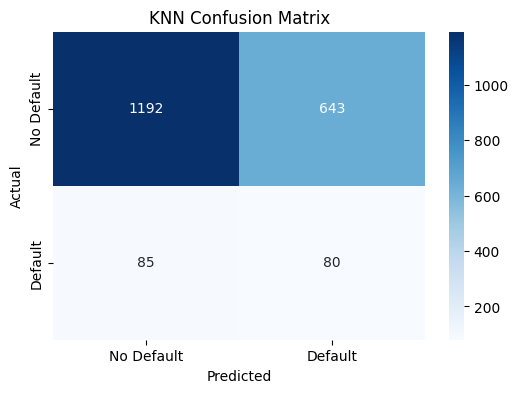

In [30]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

20. K-Fold Cross Validation

Because this is an imbalanced classification problem, use:

In [31]:
StratifiedKFold

sklearn.model_selection._split.StratifiedKFold

In [32]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1"
]

In [35]:
cv_results = cross_validate(
    knn_pipeline,
    X,
    y,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)
print(cv_results)

{'fit_time': array([10.1984365 ,  9.2896874 ,  9.800704  , 10.14841652,  2.90619564]), 'score_time': array([0.92463756, 1.67304516, 0.72083235, 0.74985075, 0.36331987]), 'test_accuracy': array([0.612 , 0.6405, 0.635 , 0.6035, 0.6295]), 'test_precision': array([0.0984252 , 0.10300429, 0.10818308, 0.09114583, 0.11394102]), 'test_recall': array([0.45731707, 0.43902439, 0.47272727, 0.42424242, 0.51515152]), 'test_f1': array([0.16198704, 0.16685979, 0.17607223, 0.15005359, 0.18660812])}


21. Display K-Fold Results

In [36]:
print("5-FOLD CROSS VALIDATION")

print(
    "Accuracy:",
    cv_results["test_accuracy"].mean()
)

print(
    "Precision:",
    cv_results["test_precision"].mean()
)

print(
    "Recall:",
    cv_results["test_recall"].mean()
)

print(
    "F1 Score:",
    cv_results["test_f1"].mean()
)

5-FOLD CROSS VALIDATION
Accuracy: 0.6241
Precision: 0.10293988397056841
Recall: 0.4616925351071693
F1 Score: 0.16831615614696793


In [37]:
for i in range(5):

    print(f"\nFold {i+1}")

    print(
        "Accuracy:",
        cv_results["test_accuracy"][i]
    )

    print(
        "Precision:",
        cv_results["test_precision"][i]
    )

    print(
        "Recall:",
        cv_results["test_recall"][i]
    )

    print(
        "F1:",
        cv_results["test_f1"][i]
    )


Fold 1
Accuracy: 0.612
Precision: 0.0984251968503937
Recall: 0.4573170731707317
F1: 0.16198704103671707

Fold 2
Accuracy: 0.6405
Precision: 0.10300429184549356
Recall: 0.43902439024390244
F1: 0.16685979142526072

Fold 3
Accuracy: 0.635
Precision: 0.10818307905686546
Recall: 0.4727272727272727
F1: 0.17607223476297967

Fold 4
Accuracy: 0.6035
Precision: 0.09114583333333333
Recall: 0.42424242424242425
F1: 0.15005359056806003

Fold 5
Accuracy: 0.6295
Precision: 0.11394101876675604
Recall: 0.5151515151515151
F1: 0.18660812294182216


22. Checking the Best K Value

In [39]:
k_values = [3, 5, 7, 9, 11]

results = []

for k in k_values:

    model = Pipeline([

        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "smotetomek",
            SMOTETomek(random_state=42)
        ),

        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=k,
                weights="distance"
            )
        )
    ])

    scores = cross_validate(
        model,
        X,
        y,
        cv=skf,
        scoring=["precision", "recall", "f1"],
        n_jobs=-1
    )

    results.append({
        "K": k,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

In [41]:
results_df = pd.DataFrame(results)

print(results_df)

    K  Precision    Recall        F1
0   3   0.109100  0.408234  0.172127
1   5   0.102940  0.461693  0.168316
2   7   0.103777  0.523636  0.173202
3   9   0.102056  0.566171  0.172930
4  11   0.101123  0.600177  0.173077


23. Plotting  K vs F1 Score

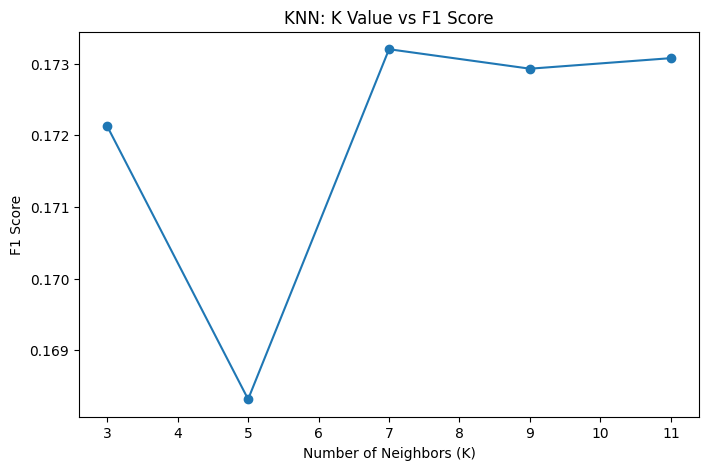

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["F1"],
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("F1 Score")
plt.title("KNN: K Value vs F1 Score")

plt.show()

24. Training Final Model

In [43]:
final_knn = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "smotetomek",
        SMOTETomek(random_state=42)
    ),

    (
        "knn",
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance"
        )
    )
])

In [44]:
final_knn.fit(X, y)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('smotetomek', SMOTETomek(random_state=42)),
                ('knn',
                 KNeighborsClassifier(n_neighbors=7, weights='distance'))])